# Evaluate results of Beast run - Compare skygrid and constcoal prior for a Pertussis data set in France between 2010 and 2024

In [1]:
import pandas as pd
import numpy as np

import re

import matplotlib.pyplot as plt
import seaborn as sns

import dendropy

from evaluation_helpers import *

## Distribution of sampling times

<Axes: title={'center': 'Negative cumulative distribution of sampling dates'}, xlabel='Decimal year', ylabel='Samples collected at or after date'>

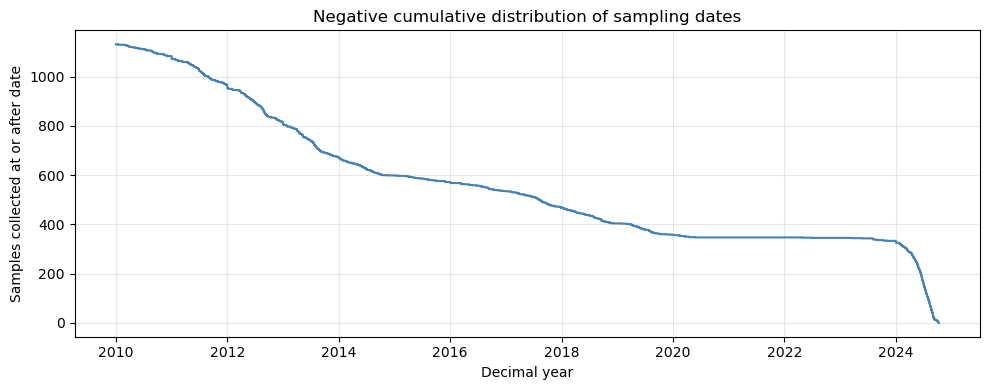

In [2]:
meta_df = pd.read_csv("data/pertussis_france/full_metadata.csv")
meta_df.sort_values("decimal_year", inplace=True)
plot_sampling_neg_cumulative(meta_df)

## Analyze inferred population trajectory and general tree statistics
- population trajectories
- constant-size population estimate and skygrid estimates 
- root height
- tree length

,median,hpd_lower,hpd_upper
skygrid,65.682007,44.034267,94.930862
constcoal,80.527602,55.256447,115.263547


<Axes: title={'center': 'Pertussis France 2010–2024'}, xlabel='Time (years)', ylabel='Effective Population Size'>

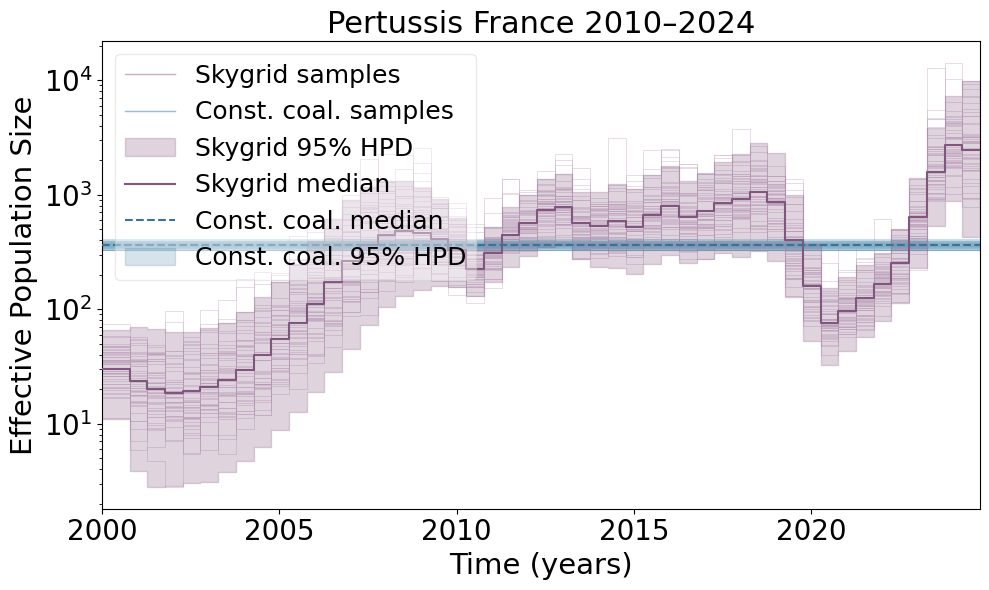

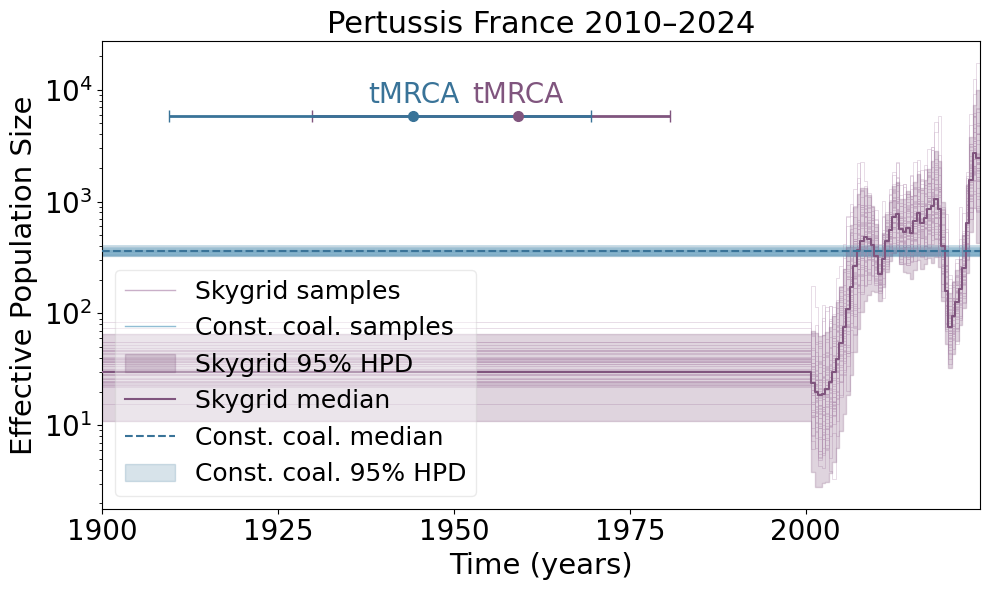

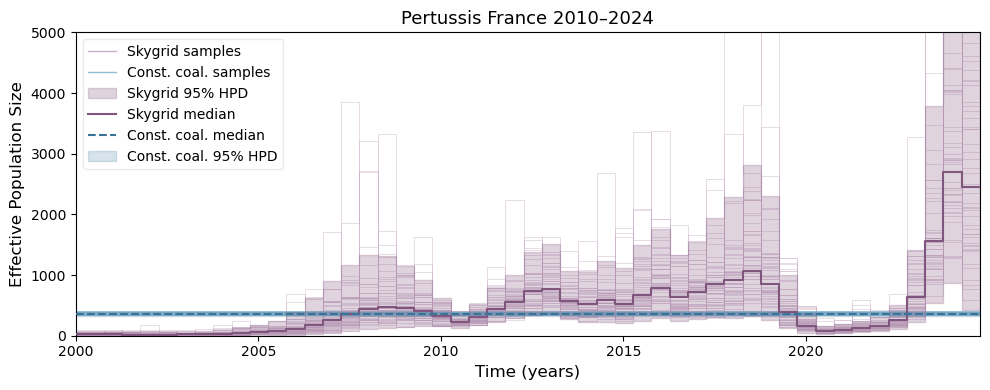

In [3]:
skygrid_log = read_beast_log('data/pertussis_france/beast_skygrid/pertussis_skygrid_2010_2024_allseeds.log')
constcoal_log = read_beast_log('data/pertussis_france/beast_constcoal/pertussis_constcoal_2010_2024_allseeds.log')

rootheight_df = compute_root_height_summary(skygrid_log, constcoal_log)
display(rootheight_df)

sky_summary = compute_skygrid_summary(skygrid_log, t_present=2024.7704918032787, end_time=1900)
const_summary = compute_constcoal_summary(constcoal_log)

plot_pertussis_skygrid(sky_summary, const_summary, title='Pertussis France 2010–2024', cutoff=2000, save_path='figures/pertussis_popsize.pdf',
                       fontsize=21, tick_fontsize=20, legend_fontsize=18, title_fontsize= 22, figsize=(10, 6))
plot_pertussis_skygrid(sky_summary, const_summary, root_height_summary=rootheight_df, title='Pertussis France 2010–2024', save_path='figures/pertussis_popsize_tmrca.pdf',
                       fontsize=21, tick_fontsize=20, legend_fontsize=18, title_fontsize= 22, figsize=(10, 6))
plot_pertussis_skygrid(sky_summary, const_summary, title='Pertussis France 2010–2024', cutoff=2000, log_scale=False, y_range = (0, 5000))

In [4]:
treelength_df = compute_root_height_summary(skygrid_log, constcoal_log, column = 'treeLength')
display(treelength_df)

,median,hpd_lower,hpd_upper
skygrid,4158.412562,3932.425447,4403.037622
constcoal,4258.008780,4006.157434,4538.124745


In [5]:
# constant population size summary
const_summary

{'median': np.float64(361.8279571855969),
 'hpd_lower': np.float64(325.22265289794234),
 'hpd_upper': np.float64(398.99944497032055),
 'samples': array([355.99924115, 390.0981181 , 366.18214052, ..., 364.10210281,
        374.60386272, 387.67773786], shape=(140564,))}

In [6]:
# skygrid population size summary
sky_summary['median']

array([2456.16485156, 2693.7431719 , 1561.46557583,  639.35287826,
        254.53019039,  164.3762467 ,  125.57162162,   95.40659727,
         75.97128618,  158.0818725 ,  397.71854049,  859.45231311,
       1058.79749394,  914.40214303,  852.01783639,  717.26940784,
        638.5700328 ,  791.12150968,  669.24945868,  524.70701822,
        585.21380908,  530.98789441,  570.44422205,  777.46552847,
        729.46066573,  559.79506134,  442.32686295,  308.47879597,
        225.254127  ,  326.70776475,  412.84419612,  459.80057517,
        479.78246745,  448.24013117,  365.97875745,  263.93296109,
        171.0565627 ,  110.12685289,   76.36642164,   54.78838549,
         39.47120983,   29.69287968,   24.2898513 ,   21.0588525 ,
         19.18567884,   18.63980181,   20.01712843,   23.66911657,
         30.25752462])

In [7]:
# investigate root height only of tips that were sampled after 2020 / 2022 from summary tree

sky_tree = read_summary_tree('data/pertussis_france/beast_skygrid/pertussis_skygrid_2010_2024_allseeds_summary_keepheights.tree')
const_tree = read_summary_tree('data/pertussis_france/beast_constcoal/pertussis_constcoal_2010_2024_allseeds_summary_keepheights.tree')

print(f"Skyline: {subtree_root_height(sky_tree, meta_df, cutoff_year=2020)}")
print(f"Constcoal: {subtree_root_height(const_tree, meta_df, cutoff_year=2020)}")
print()
print(f"Skyline: {subtree_root_height(sky_tree, meta_df, cutoff_year=2022)}")
print(f"Constcoal: {subtree_root_height(const_tree, meta_df, cutoff_year=2022)}")

Skyline: {'n_tips': 358, 'height_median': 52.7104721422679, 'height_hpd': (39.913670185939736, 68.83721378056089)}
Constcoal: {'n_tips': 358, 'height_median': 80.52749945010197, 'height_hpd': (55.25644732909814, 115.2635465777874)}

Skyline: {'n_tips': 347, 'height_median': 52.7104721422679, 'height_hpd': (39.913670185939736, 68.83721378056089)}
Constcoal: {'n_tips': 347, 'height_median': 80.52749945010197, 'height_hpd': (55.25644732909814, 115.2635465777874)}


## Compute summary tree:

We obtain summary trees using _treeannotator_:

```
scripts/run_treeannotator.sh \
--skygrid-in data/pertussis_france/beast_skygrid/pertussis_skygrid_2010_2024_allseeds.trees \
--skygrid-out data/pertussis_france/beast_skygrid/pertussis_skygrid_2010_2024_allseeds_summary_keepheights.tree \
--constcoal-in  data/pertussis_france/beast_constcoal/pertussis_constcoal_2010_2024_allseeds.trees \
--constcoal-out data/pertussis_france/beast_constcoal/pertussis_constcoal_2010_2024_allseeds_summary_keepheights.tree \
--heights keep
```

<Axes: ylabel='Year'>

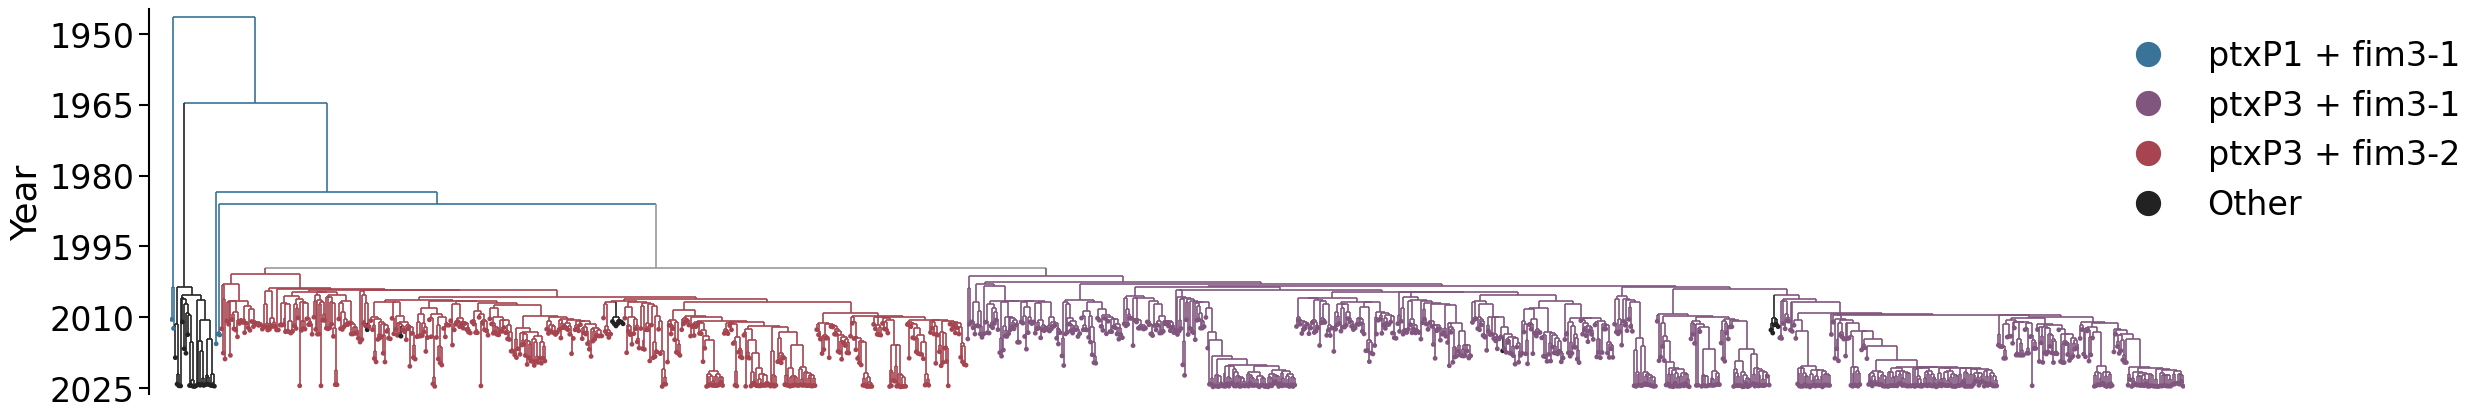

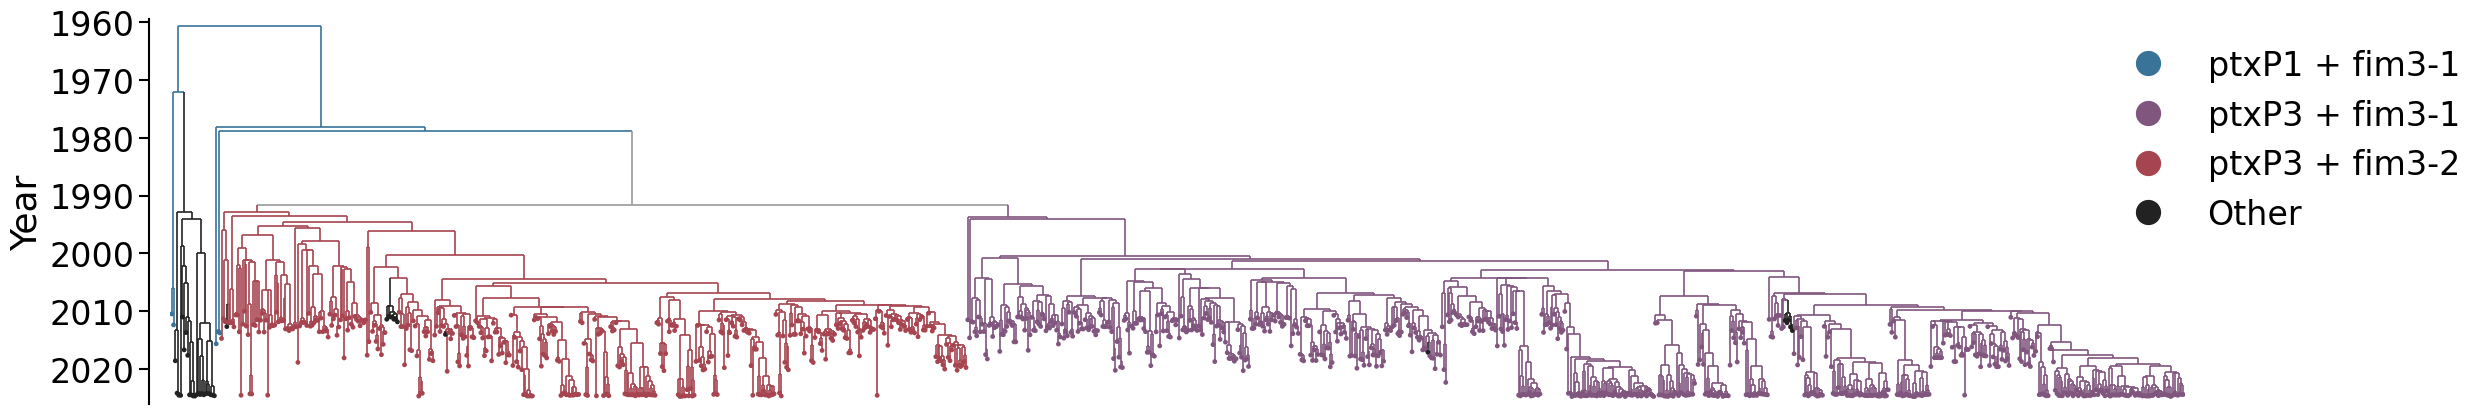

In [8]:
# skygrid
plot_timetree(
      'data/pertussis_france/beast_skygrid/pertussis_skygrid_2010_2024_allseeds_summary_keepheights.tree',
      'data/pertussis_france/full_metadata.csv',
      save_path='figures/pertussis_skygrid_timetree.pdf',
      color_branches = True,
      figsize=(26, 5)
  )

# constant-size coalescent
plot_timetree(
      'data/pertussis_france/beast_constcoal/pertussis_constcoal_2010_2024_allseeds_summary_keepheights.tree',
      'data/pertussis_france/full_metadata.csv',
      save_path='figures/pertussis_constcoal_timetree.pdf',
      color_branches = True,
      figsize=(26, 5)
  )

## Compare tree topology
We compare the topology between trees inferred under the skygrid and constant-size coalescent prior, by plotting a tanglegram of the two summary trees and coloring it by _ptxP_ and _fim3_ subtype to see the broader structure.

<Axes: >

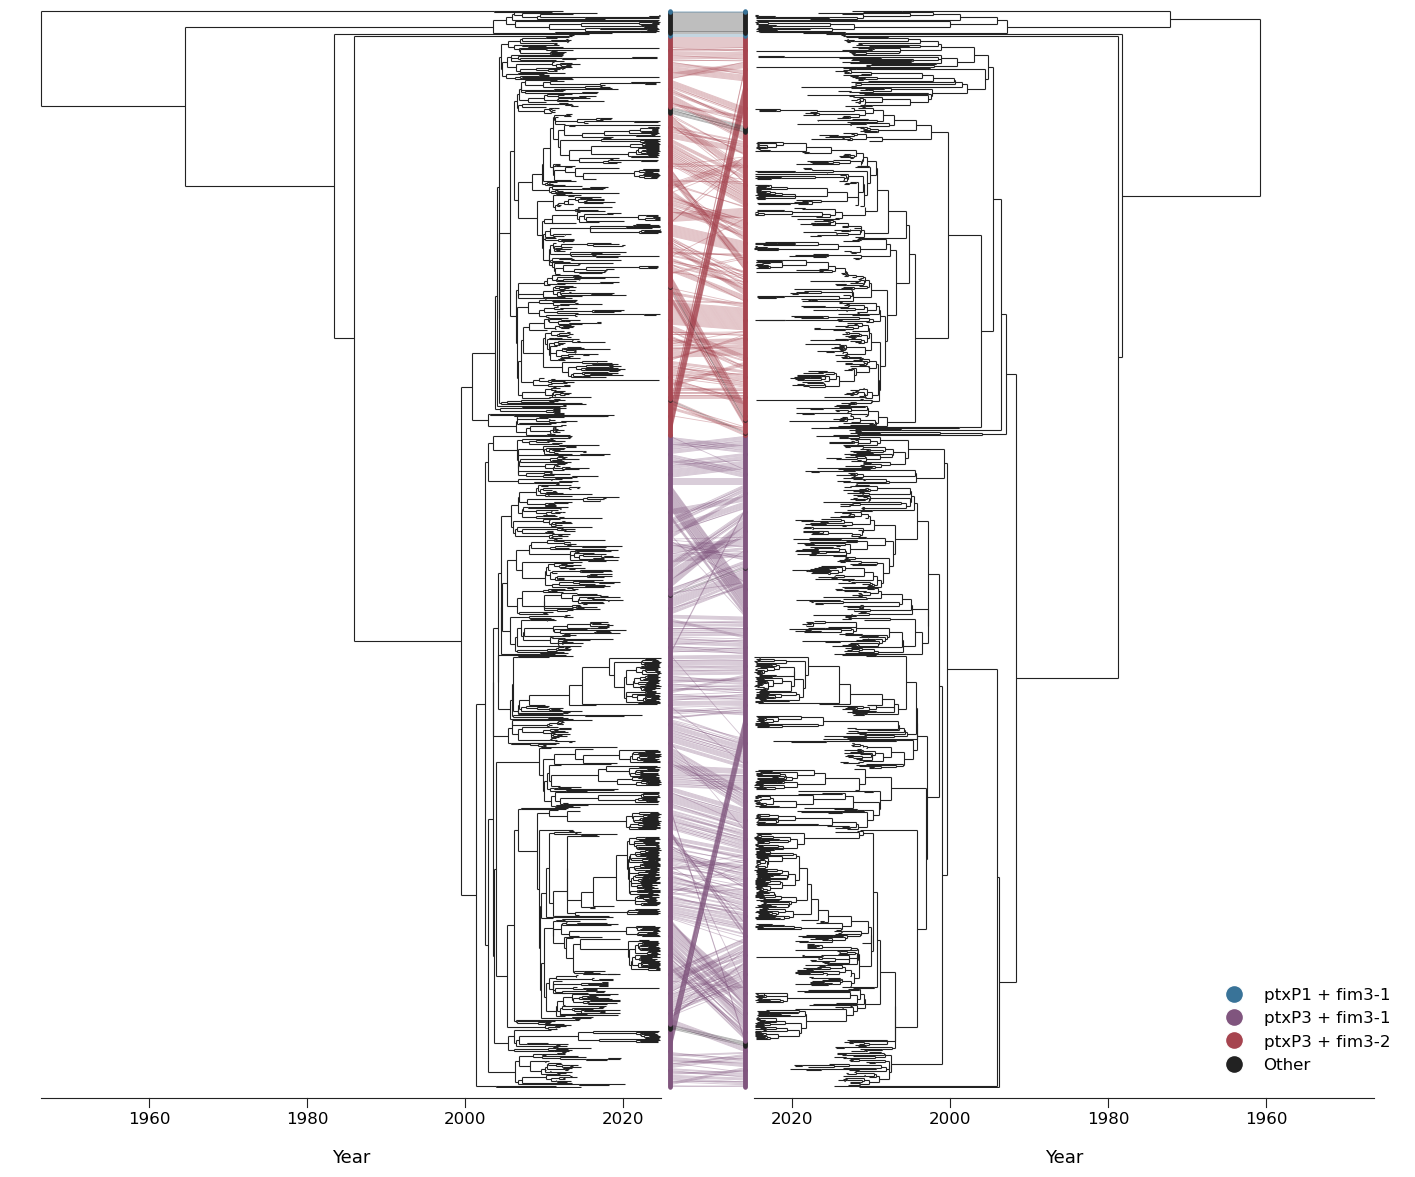

In [9]:
plot_tanglegram(
      'data/pertussis_france/beast_skygrid/pertussis_skygrid_2010_2024_allseeds_summary_keepheights.tree',
      'data/pertussis_france/beast_constcoal/pertussis_constcoal_2010_2024_allseeds_summary_keepheights.tree',
      'data/pertussis_france/full_metadata.csv',
      color_branches = False,
      save_path='figures/tanglegram.pdf',
  )

# skygrid left, const. coal right

<Axes: >

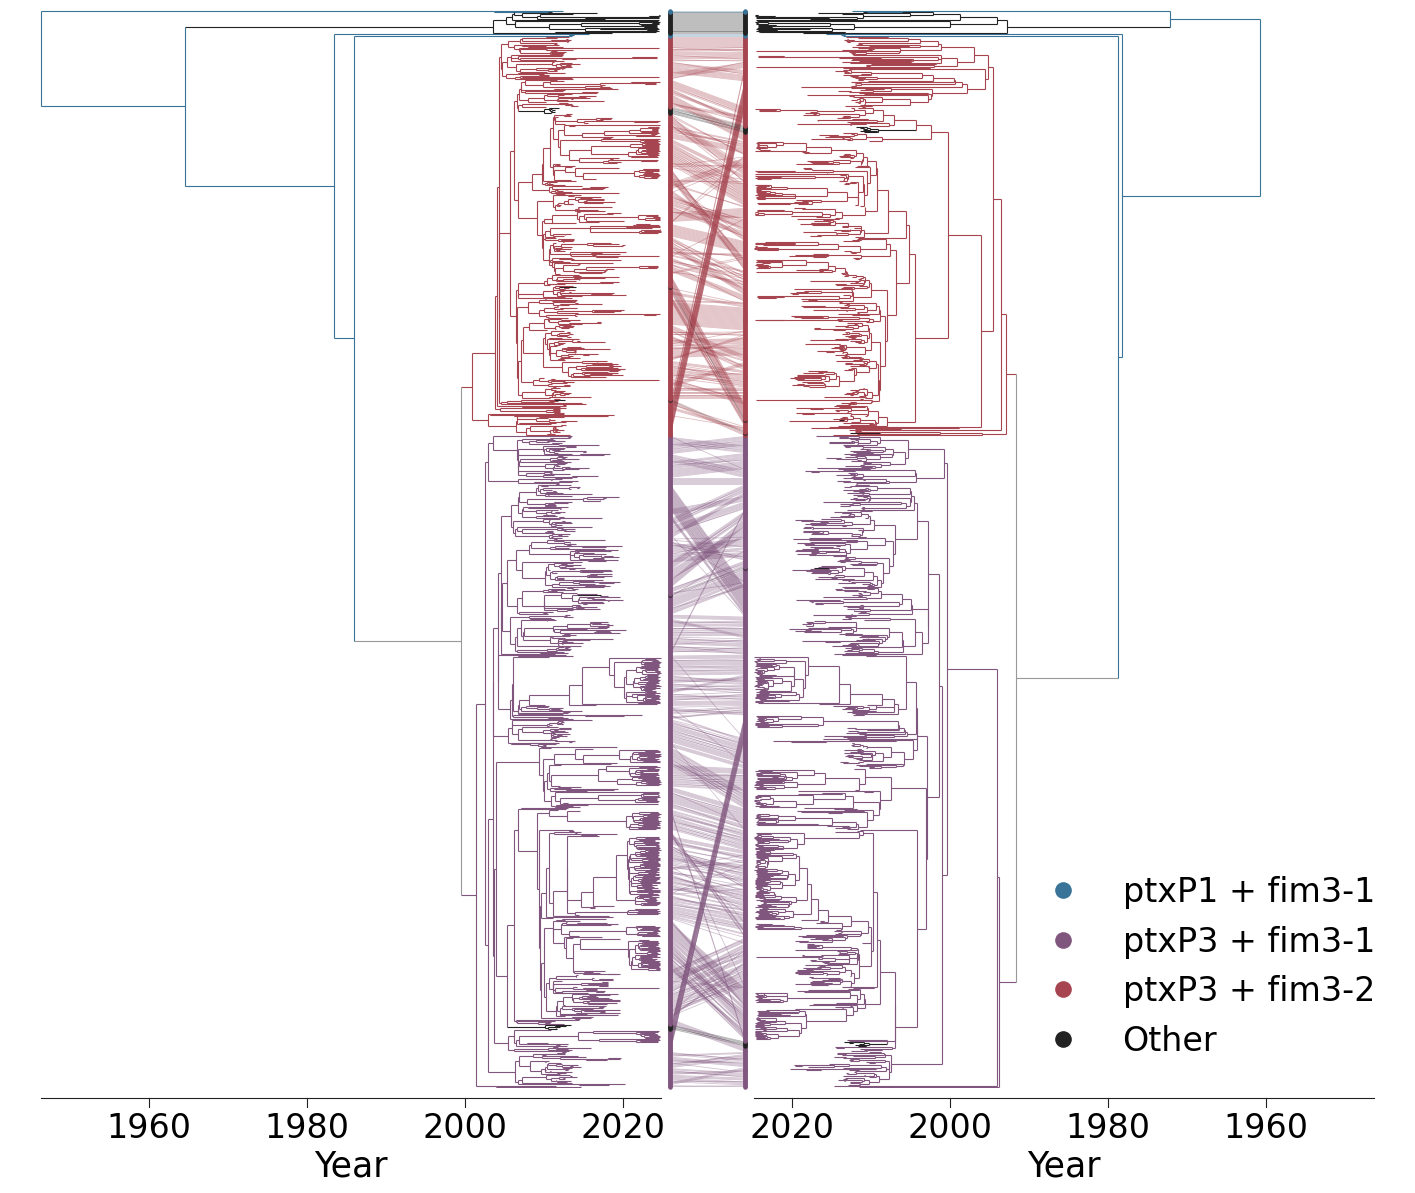

In [10]:
plot_tanglegram(
      'data/pertussis_france/beast_skygrid/pertussis_skygrid_2010_2024_allseeds_summary_keepheights.tree',
      'data/pertussis_france/beast_constcoal/pertussis_constcoal_2010_2024_allseeds_summary_keepheights.tree',
      'data/pertussis_france/full_metadata.csv',
      color_branches = True, legend_fontsize = 24,
      save_path='figures/tanglegram_fitch.pdf',
  )

To see whether we observe similar fine-scale changes in topology between tips within posterior samples, we compare two skygrid sample trees:


<Axes: >

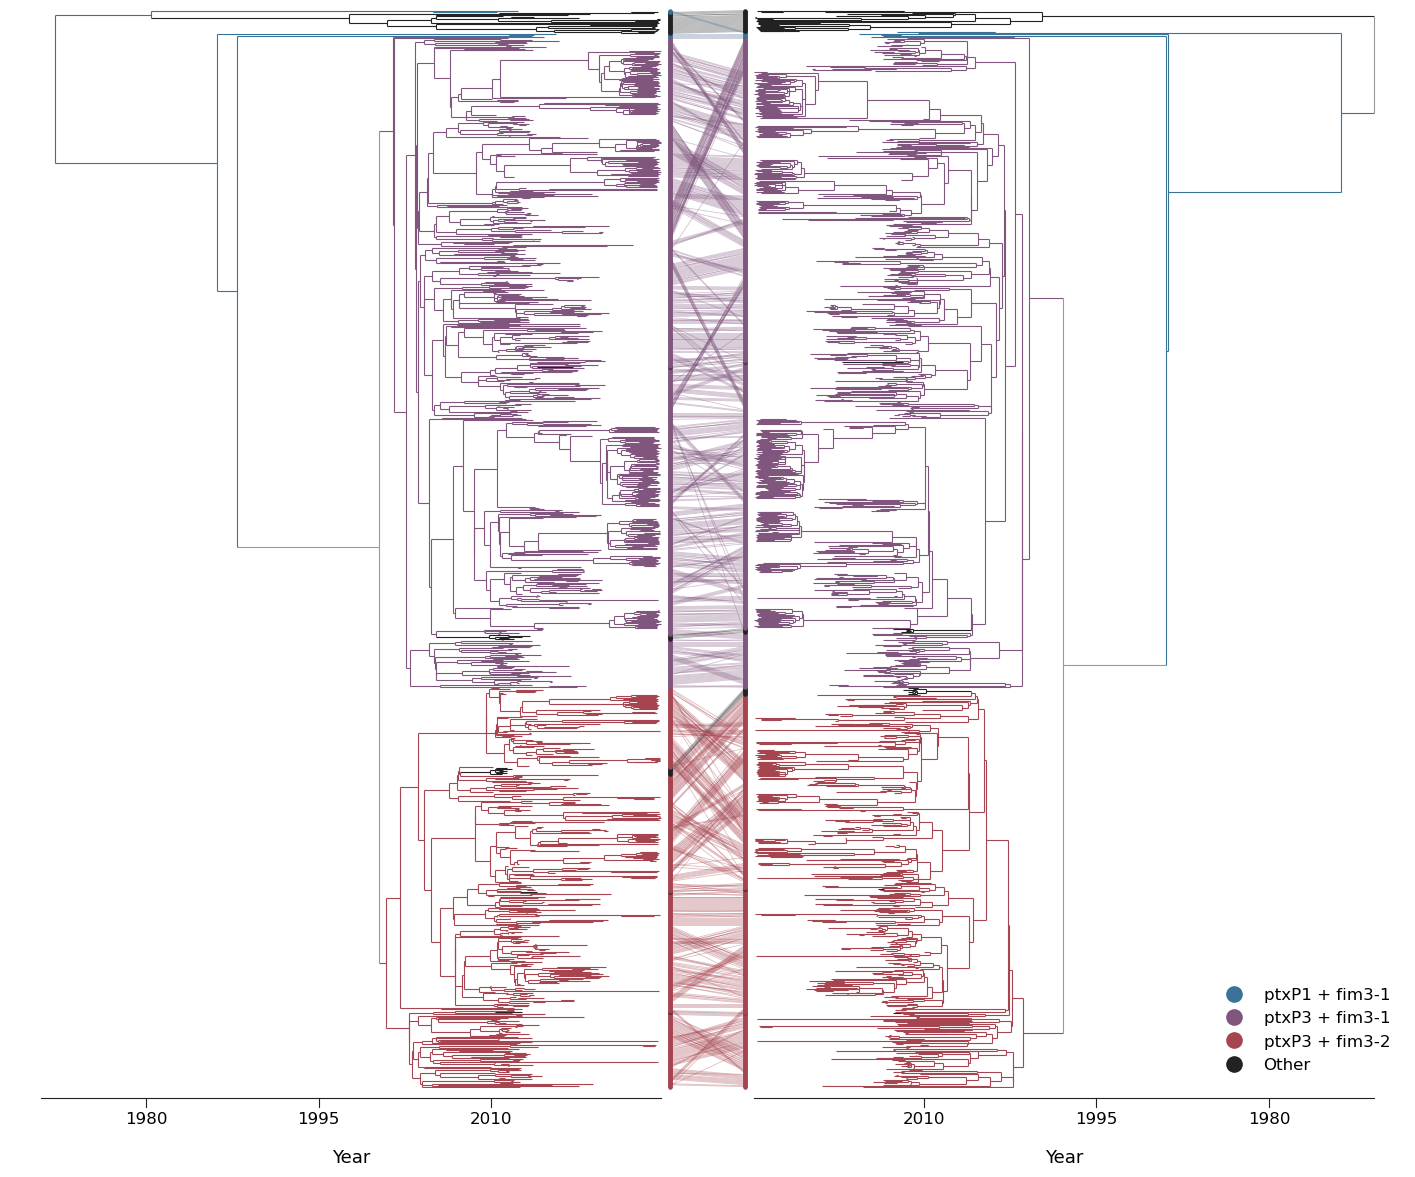

In [12]:
plot_tanglegram(
      'data/pertussis_france/beast_skygrid/skygrid_sample_tree1.nwk',
      'data/pertussis_france/beast_skygrid/skygrid_sample_tree2.nwk',
      'data/pertussis_france/full_metadata.csv',
      color_branches = True,
      save_path='figures/twiceskygrid_tanglegram.pdf',
  )

We next compare topologies by considering the Robinson Foulds Distance: How many internal branch-induced splits are shared or not shared between two trees. The maximal distance is 2 * (n - 3) where n - 3 is the number of internal splits exluding the root and trivial leaf splits (2 * because in case of a missplit, both trees would be split wrongly)

In [ ]:
# transform summary trees to newick format

for src, dst in [
      ("data/pertussis_france/beast_constcoal/pertussis_constcoal_2010_2024_allseeds_summary_keepheights.tree", "data/pertussis_france/beast_constcoal/constcoal_summary.nwk"),
      ("data/pertussis_france/beast_skygrid/pertussis_skygrid_2010_2024_allseeds_summary_keepheights.tree", "data/pertussis_france/beast_skygrid/skygrid_summary.nwk"),
  ]:
    tree = dendropy.Tree.get(path=src, schema="nexus")
    #for edge in tree.preorder_edge_iter():
    #    if edge.length is not None and edge.length < 0:
    #        edge.length = 1e-6
    tree.write(path=dst, schema="newick", suppress_annotations=True, suppress_rooting=True)

In [13]:
# calculate Robinson-Foulds distance between the two summary trees

robinson_foulds(
    "data/pertussis_france/beast_constcoal/constcoal_summary.nwk",
    "data/pertussis_france/beast_skygrid/skygrid_summary.nwk"
)

{'rf': 1154, 'rf_max': 2260, 'rf_normalized': 0.5106194690265486}

In [ ]:
# compute Robinson-Foulds distances between 1000 posterior subsamples of the skygrid tree, the constant-size coalescent tree, and between the two

tns = dendropy.TaxonNamespace()

sky_trees   = load_trees('data/pertussis_france/beast_skygrid/pertussis_skygrid_2010_2024_allseeds_10k.subsampled1000.trees', taxon_namespace=tns)
const_trees = load_trees('data/pertussis_france/beast_constcoal/pertussis_constcoal_2010_2024_allseeds_10k.subsampled1000.trees', taxon_namespace=tns)

topology_dist_df = compute_tree_distances(sky_trees, const_trees)
topology_dist_df['rf_norm'] = topology_dist_df['rf'] / 2262
topology_dist_df.to_csv('data/pertussis_france/topology_distances_1000.csv', index=False)

Computing within-skygrid distances (537166 pairs) …
  2000/537166
  4000/537166
  6000/537166
  8000/537166
  10000/537166
  12000/537166
  14000/537166
  16000/537166
  18000/537166
  20000/537166
  22000/537166
  24000/537166
  26000/537166
  28000/537166
  30000/537166
  32000/537166
  34000/537166
  36000/537166
  38000/537166
  40000/537166
  42000/537166
  44000/537166
  46000/537166
  48000/537166
  50000/537166
  52000/537166
  54000/537166
  56000/537166
  58000/537166
  60000/537166
  62000/537166
  64000/537166
  66000/537166
  68000/537166
  70000/537166
  72000/537166
  74000/537166
  76000/537166
  78000/537166
  80000/537166
  82000/537166
  84000/537166
  86000/537166
  88000/537166
  90000/537166
  92000/537166
  94000/537166
  96000/537166
  98000/537166
  100000/537166
  102000/537166
  104000/537166
  106000/537166
  108000/537166
  110000/537166
  112000/537166
  114000/537166
  116000/537166
  118000/537166
  120000/537166
  122000/537166
  124000/537166
  126000/

                      count      mean       std       min       25%       50%  \
comparison                                                                      
between           1040111.0  0.509493  0.010132  0.460654  0.503095  0.509284   
within_constcoal   502503.0  0.501934  0.011242  0.429708  0.494253  0.502210   
within_skygrid     537166.0  0.509930  0.010586  0.457118  0.503095  0.510168   

                       75%       max  
comparison                            
between           0.516357  0.554377  
within_constcoal  0.509284  0.549956  
within_skygrid    0.517241  0.553492  


<Axes: xlabel='Normalised RF distance', ylabel='Density'>

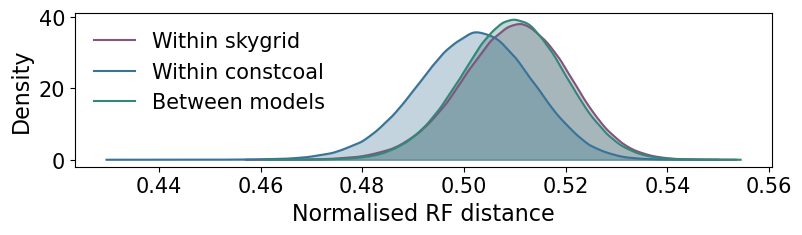

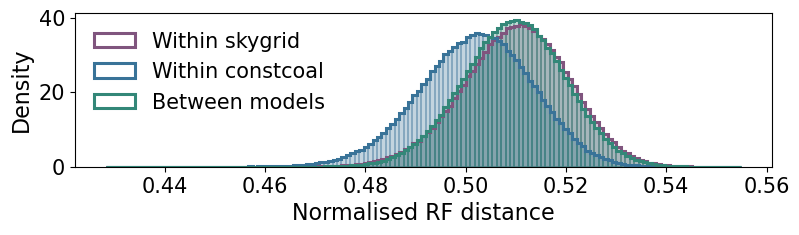

In [14]:
# visualize the distribution of Robinson-Foulds distances

topology_dist_df = pd.read_csv('data/pertussis_france/topology_distances_1000.csv')
print(topology_dist_df.groupby('comparison')['rf_norm'].describe())

plot_rf_distributions(topology_dist_df, normalized=True, save_path='figures/rf_distributions.pdf', figsize=(9, 2), tick_fontsize= 15, legend_fontsize=15, fontsize= 16)
plot_rf_distributions(topology_dist_df, normalized=True, mode = 'hist', save_path='figures/rf_distributions_hist.pdf', figsize=(9, 2), tick_fontsize= 15, legend_fontsize=15, fontsize= 16)

# Compare pairwise tip-to-MRCA distances

We consider more detailed changes in tree dating by considering pairwise tip-to-MRCA distances for a subset of 1000 posterior sample trees. For each possible tip pair, we consider their time to their MRCA over all posterior samples and obtain medians and HPD intervals. Results are obtained by running `scripts/compute_coalescent_distances.py` with `scripts/run_coalescent_distances.sh`.

To specifically investigate the bottleneck, we consider tips sampled after the beginning of the pandemic (after 2020.0).

In [15]:
coalescent_tip_dist = pd.read_csv("data/pertussis_france/coalescent_tip_distances_1000.tsv", sep = "\t",)

cutoff_date = 2020.0
bottleneck_dist_df = coalescent_tip_dist[(coalescent_tip_dist['tip1_date'] >= cutoff_date) & (coalescent_tip_dist['tip2_date'] >= cutoff_date)]

coalescent_tip_dist.head()

,tip1,tip2,tip1_date,tip2_date,skygrid_tip1_to_mrca_median,skygrid_tip1_to_mrca_hpd_lower,skygrid_tip1_to_mrca_hpd_upper,skygrid_tip2_to_mrca_median,skygrid_tip2_to_mrca_hpd_lower,skygrid_tip2_to_mrca_hpd_upper,...,abs_diff_tip1_hpd_upper,rel_diff_tip1_median,rel_diff_tip1_hpd_lower,rel_diff_tip1_hpd_upper,abs_diff_tip2_median,abs_diff_tip2_hpd_lower,abs_diff_tip2_hpd_upper,rel_diff_tip2_median,rel_diff_tip2_hpd_lower,rel_diff_tip2_hpd_upper
0,ERR2102126,ERR2102127,2011.394521,2011.394521,1.894169,0.824687,3.190771,1.894169,0.824687,3.190771,...,2.175013,0.140568,-0.603574,1.501543,0.266147,-1.432970,2.175013,0.140568,-0.603574,1.501543
1,ERR2102126,ERR2102128,2011.394521,2011.394521,1.030994,0.500441,1.758497,1.030994,0.500441,1.758497,...,1.292870,0.173515,-0.577803,1.444947,0.169718,-0.866073,1.292870,0.173515,-0.577803,1.444947
2,ERR2102126,ERR2102129,2011.394521,2011.849315,1.032683,0.523556,1.831523,1.487478,0.978351,2.286318,...,1.204369,0.176911,-0.608552,1.410037,0.165284,-0.926345,1.204369,0.118216,-0.477913,0.861756
3,ERR2102126,ERR2102130,2011.394521,2011.945205,9.507640,7.604254,12.374270,10.058325,8.154939,12.924955,...,12.102163,0.649310,-0.018084,1.319622,6.288065,0.787595,12.102163,0.613331,-0.017261,1.243928
4,ERR2102126,ERR2102131,2011.394521,2011.953425,9.507640,7.604254,12.374270,10.066544,8.163158,12.933174,...,12.102163,0.649310,-0.018084,1.319622,6.288065,0.787595,12.102163,0.612747,-0.017249,1.242864


(<Axes: ylabel='Const. coal.'>,
 <Axes: xlabel='Skygrid', ylabel='Diff. (years)'>)

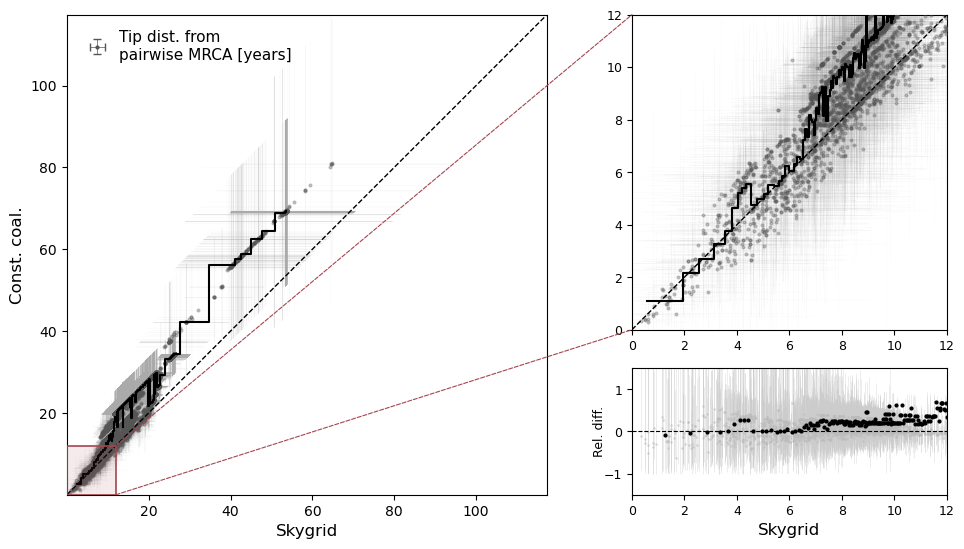

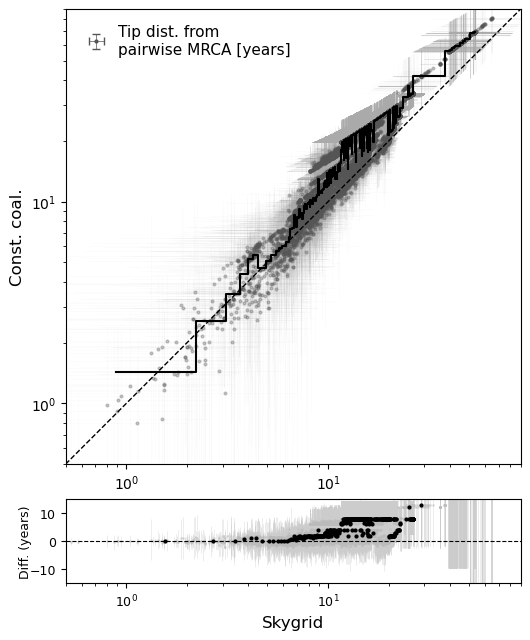

In [16]:
# all tips

plot_pairwise_distances(coalescent_tip_dist, ax=None, title="", n_subsample=10000, n_subsample_zoom=3000, log_scale = False,
                        diff_plot = True, diff_mode='relative', diff_axis_range=(-1.5,1.5),
                        point_alpha = 0.3, errorbar_alpha = 0.05, markersize=2, elinewidth=0.5, axis_range = None, zoom_range = (0, 12),
                        save_path = "figures/pairwise_tip_distances_reldiff.pdf", fontsize = 12,
                        running_avg = True, window_size = 10000, window_overlap = 5000, window_size_zoom = 2000, window_overlap_zoom=0, running_avg_style='steps', running_avg_color = "black")

plot_pairwise_distances(coalescent_tip_dist, ax=None, title="", n_subsample=20000, log_scale = True,
                        diff_plot = True, diff_mode='absolute', diff_axis_range=(-15,15),
                        point_alpha = 0.3, errorbar_alpha = 0.05, markersize=2, elinewidth=0.5, axis_range = (0.5,90),
                        save_path = "figures/pairwise_tip_distances_log_absdiff.pdf", fontsize = 12,
                        running_avg = True, window_size = 3000, window_overlap = 0, running_avg_style='steps', running_avg_color = "black")

(<Axes: xlabel='Skygrid', ylabel='Const. coal.'>,
 <Axes: >,
 <Axes: xlabel='Skygrid', ylabel='Rel. diff.'>)

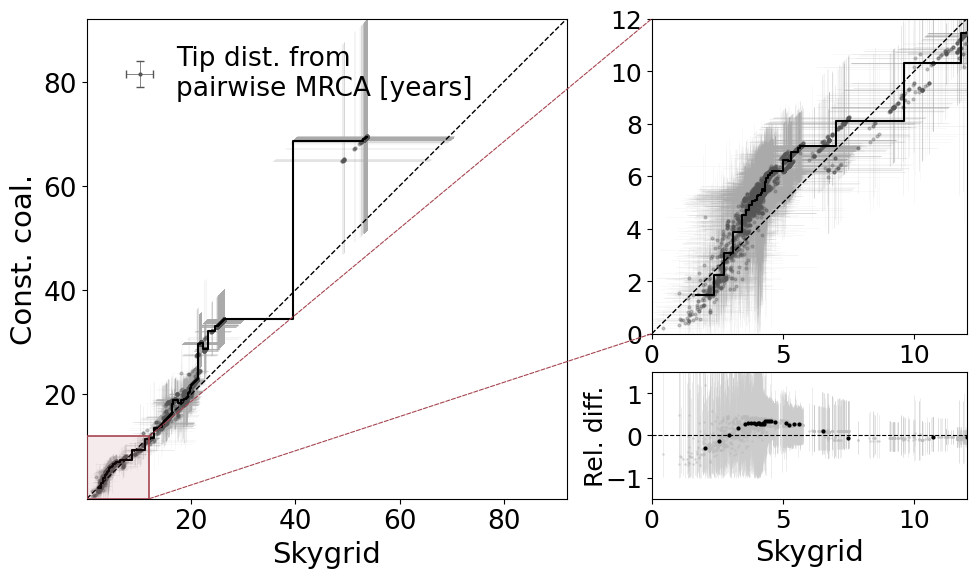

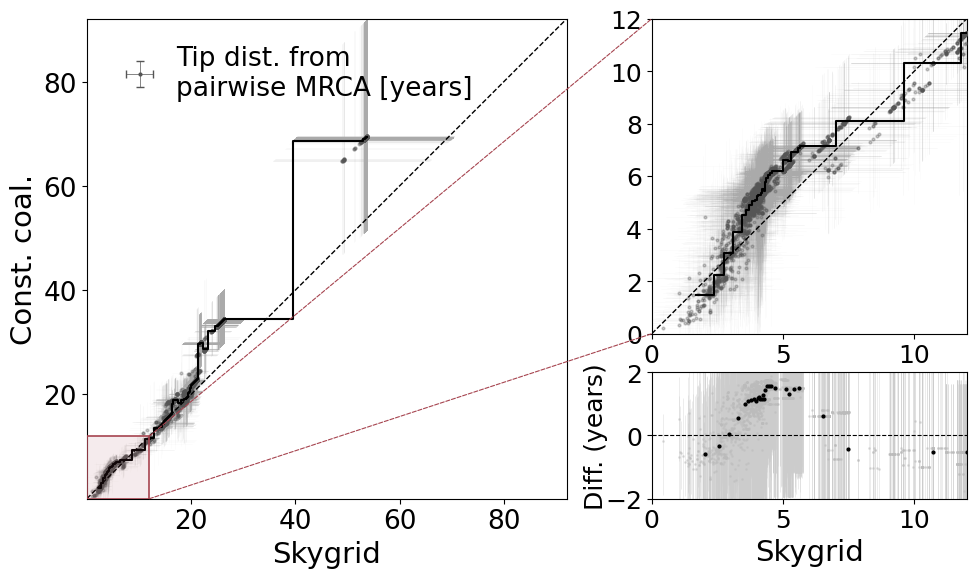

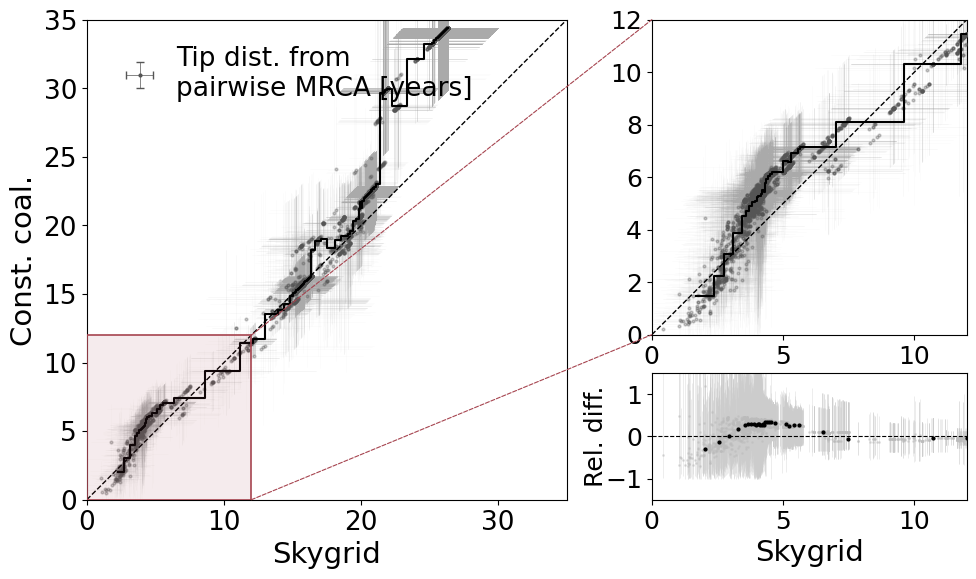

In [17]:
# all tips after the start of the bottleneck (2020)

plot_pairwise_distances(bottleneck_dist_df, ax=None, title="", n_subsample=10000, n_subsample_zoom=3000, log_scale = False,
                        diff_plot = True, diff_mode='relative', diff_axis_range=(-1.5,1.5),  diff_hpd=True,
                        point_alpha = 0.3, errorbar_alpha = 0.1, markersize=2, elinewidth=0.5, axis_range = None, zoom_range = (0, 12),
                        save_path = "figures/bottleneck_pairwise_tip_distances_reldiff.pdf", 
                        tick_fontsize = 19, legend_fontsize = 19,fontsize = 21,
                        running_avg = True, window_size = 1000, window_overlap = 500, window_size_zoom = 400, window_overlap_zoom=0, running_avg_style='steps', running_avg_color = "black")

plot_pairwise_distances(bottleneck_dist_df, ax=None, title="", n_subsample=10000, n_subsample_zoom=3000, log_scale = False,
                        diff_plot = True, diff_mode='absolute', diff_axis_range=(-2,2),
                        point_alpha = 0.3, errorbar_alpha = 0.05, markersize=2, elinewidth=0.5, axis_range = None, zoom_range = (0, 12),
                        save_path = "figures/bottleneck_pairwise_tip_distances_absdiff.pdf",
                        tick_fontsize = 19, legend_fontsize = 19,fontsize = 21,
                        running_avg = True, window_size = 1000, window_overlap = 500, window_size_zoom = 400, window_overlap_zoom=0, running_avg_style='steps', running_avg_color = "black")

plot_pairwise_distances(bottleneck_dist_df, ax=None, title="", n_subsample=10000, n_subsample_zoom=3000, log_scale = False,
                        diff_plot = True, diff_mode='relative', diff_axis_range=(-1.5,1.5),
                        point_alpha = 0.3, errorbar_alpha = 0.05, markersize=2, elinewidth=0.5, axis_range = (0, 35), zoom_range = (0, 12),
                        save_path = "figures/bottleneck_pairwise_tip_distances_small_reldiff.pdf",
                        tick_fontsize = 19, legend_fontsize = 19,fontsize = 21,
                        running_avg = True, window_size = 1000, window_overlap = 500, window_size_zoom = 400, window_overlap_zoom=0, running_avg_style='steps', running_avg_color = "black")